# Preprocessing 3: Feature engineering and scaling
**Input:** the split posts from notebook 2. **Output:** the `preprocessed/` folder that the modelling notebooks use.

| Step | What it does |
|---|---|
| 6 | **Feature engineering**: text meta-features, image features, TF-IDF, CLIP |
| 7 | **Normalisation and standardisation**, fitted on the training set only |
| 8 | Save everything for the modelling notebooks |

In [ ]:
# Make the shared code in src/ importable, wherever the repository folder is
import os, sys
root = os.getcwd()
while not os.path.isdir(os.path.join(root, "src", "mvsa")) and root != os.path.dirname(root):
    root = os.path.dirname(root)
sys.path.insert(0, os.path.join(root, "src"))

from mvsa.preprocessing import *

posts = load_state("posts_split")
REPORT = load_state("report")
SPLITS = ["train", "val", "test", "hard"]

## Step 6: Feature engineering
Four groups of features, each answering a different question:

| Group | Features | Dim | Purpose |
|---|---|---|---|
| **6a Text meta** | length, word count, #hashtags, #mentions, #URLs, #emojis, `!`, `?`, upper-case ratio, is-retweet, empty flag, VADER scores | ~15 | Cheap, interpretable signals that help explain the model |
| **6b Image** | colour histogram (8 bins × RGB), brightness, contrast, saturation, colourfulness, size, aspect ratio, greyscale flag | 24 + 8 | A colour histogram plus simple affective cues: bright, saturated images tend to read positive |
| **6c TF-IDF** | word 1–2-grams, fitted on train | ≤ 5,000 | Used by the baseline model. Bigrams capture `not good` |
| **6d CLIP** | ViT-B/32 text and image embeddings + their cosine similarity | 512 + 512 + 1 | The main features. The cosine similarity is the first **agreement feature** for the gated fusion |

The other two agreement features, the Jensen–Shannon divergence and classifier confidence, come from
the unimodal classifiers' *predictions*. They are built in the modelling stage, not here.

### 6a: Text meta-features
These are computed from the **raw** text, because cleaning removes exactly what is being counted.

In [8]:
def text_meta(raw):
    """Count simple signals in one raw caption."""
    raw = raw or ""
    letters = [c for c in raw if c.isalpha()]
    return {
        "n_chars":     len(raw),
        "n_words":     len(raw.split()),
        "n_hashtags":  len(HASHTAG_RE.findall(raw)),
        "n_mentions":  len(MENTION_RE.findall(raw)),
        "n_urls":      len(URL_RE.findall(raw)),
        "n_emojis":    count_emojis(raw),
        "n_exclaim":   raw.count("!"),
        "n_question":  raw.count("?"),
        "upper_ratio": sum(c.isupper() for c in letters) / max(1, len(letters)),
        "is_retweet":  int(bool(re.match(r"^\s*RT\b", raw))),
    }

text_feats = pd.DataFrame([text_meta(t) for t in posts["text_raw"]])
text_feats["text_empty"] = posts["text_empty"].values

# VADER is a sentiment lexicon built for social media. It's optional: it needs a small NLTK download.
try:
    if not ONLINE:
        raise RuntimeError("no internet")
    import nltk
    nltk.download("vader_lexicon", quiet=True)
    from nltk.sentiment import SentimentIntensityAnalyzer
    sia = SentimentIntensityAnalyzer()
    vader = pd.DataFrame([sia.polarity_scores(t) for t in posts["text_clean"]]).add_prefix("vader_")
    text_feats = pd.concat([text_feats, vader], axis=1)
    print("VADER scores added.")
except Exception as e:
    print(f"VADER skipped ({type(e).__name__}); everything else is unaffected.")

print(text_feats.describe().T[["mean", "std", "min", "max"]].round(3).to_string())
tick("Step 6a")

VADER scores added.
                  mean     std    min     max
n_chars         91.707  32.641  3.000  250.00
n_words         13.169   5.206  1.000   29.00
n_hashtags       1.537   2.554  0.000   15.00
n_mentions       0.773   0.979  0.000   10.00
n_urls           0.335   0.653  0.000    3.00
n_emojis         0.018   0.195  0.000    6.00
n_exclaim        0.260   0.749  0.000   15.00
n_question       0.882   5.057  0.000  117.00
upper_ratio      0.148   0.153  0.000    1.00
is_retweet       0.409   0.492  0.000    1.00
text_empty       0.009   0.096  0.000    1.00
vader_neg        0.136   0.173  0.000    1.00
vader_neu        0.708   0.208  0.000    1.00
vader_pos        0.156   0.187  0.000    1.00
vader_compound   0.051   0.518 -0.988    0.98

⏱ Step 6a took 1.8s


### 6b: Image features
The colour histogram uses 8 bins per channel, and each channel is **normalised to sum to 1**
so that image size doesn't matter. Colourfulness is the Hasler–Süsstrunk measure.

In [9]:
def image_features(path, bins=8, size=128):
    """Return one image's colour histogram and simple cues such as brightness and colourfulness."""
    with Image.open(path) as im:
        im.draft("RGB", (size * 2, size * 2))         # JPEG trick: decode at reduced resolution, much faster
        rgb = im.convert("RGB").resize((size, size))
    a = np.asarray(rgb, dtype=np.float32)
    hist = np.concatenate([np.histogram(a[..., c], bins=bins, range=(0, 256))[0] for c in range(3)])
    hist = hist.astype(np.float32) / (size * size)
    gray = a @ np.array([0.299, 0.587, 0.114], dtype=np.float32)
    sat = np.asarray(rgb.convert("HSV"), dtype=np.float32)[..., 1]
    rg, yb = a[..., 0] - a[..., 1], 0.5 * (a[..., 0] + a[..., 1]) - a[..., 2]
    colourfulness = np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean())
    meta = {
        "brightness":    gray.mean() / 255,
        "contrast":      gray.std() / 255,
        "saturation":    sat.mean() / 255,
        "colourfulness": colourfulness / 255,
        "is_grayscale":  int(np.abs(a[..., 0] - a[..., 1]).mean() < 2 and np.abs(a[..., 1] - a[..., 2]).mean() < 2),
    }
    return hist, meta

with ThreadPoolExecutor(WORKERS) as ex:
    feats = list(ex.map(image_features, posts["image_path"]))
colour_hist = np.vstack([h for h, _ in feats])
img_feats = pd.DataFrame([m for _, m in feats])
img_feats["width"]  = posts["width"].values
img_feats["height"] = posts["height"].values
img_feats["log_aspect"] = np.log(posts["width"].values / posts["height"].values)
print(img_feats.describe().T[["mean", "std", "min", "max"]].round(3).to_string())
tick("Step 6b (image features)")

                  mean      std     min       max
brightness       0.468    0.175   0.027     0.994
contrast         0.234    0.066   0.000     0.477
saturation       0.294    0.169   0.000     0.948
colourfulness    0.165    0.099   0.000     0.836
is_grayscale     0.047    0.211   0.000     1.000
width          551.114  105.118  48.000   600.000
height         528.052  220.407  48.000  1199.000
log_aspect       0.105    0.383  -1.185     1.798

⏱ Step 6b (image features) took 24.1s


### 6c: TF-IDF (fitted on train only)
`sublinear_tf` uses `1 + log(tf)`, so a word repeated five times doesn't count five times as much.
`min_df=2` drops words that appear in only one training post; they can't generalise.

In [10]:
# Learn the vocabulary from training posts only, then transform every split with it
is_train = (posts["split"] == "train").values
tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=5000, sublinear_tf=True)
tfidf.fit(posts.loc[is_train, "text_clean"])
X_tfidf = tfidf.transform(posts["text_clean"])
print(f"TF-IDF vocabulary: {len(tfidf.vocabulary_)} terms; matrix {X_tfidf.shape}")
tick("Step 6c")

TF-IDF vocabulary: 5000 terms; matrix (4839, 5000)

⏱ Step 6c took 0.3s


### 6d: CLIP embeddings (frozen ViT-B/32)
Each text and image goes through CLIP **once**, and the embeddings are saved, so every later experiment is a
fast scikit-learn fit. Texts longer than CLIP's 77-token limit are truncated; tweets rarely are.
Takes about 2–4 minutes on a Kaggle GPU. **Without a GPU it can take 20+ minutes**, so check the GPU line printed in Step 0.

In [11]:
clip_text = clip_image = clip_cos = None
if RUN_CLIP:
    import torch
    from transformers import CLIPModel, CLIPProcessor
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = CLIPModel.from_pretrained(CLIP_MODEL).to(device).eval()
    proc  = CLIPProcessor.from_pretrained(CLIP_MODEL)
    max_len = model.config.text_config.max_position_embeddings        # 77 for CLIP

    def as_tensor(out):   # newer transformers versions return an output object instead of a tensor
        return out if torch.is_tensor(out) else out.pooler_output

    def load_for_clip(path):
        with Image.open(path) as im:
            im.draft("RGB", (224, 224))                # CLIP only needs 224×224, so skip decoding full size
            return im.convert("RGB")

    @torch.no_grad()
    def clip_encode(texts, paths, bs=128 if device == "cuda" else 32):
        """Embed all posts in batches and scale each vector to unit length. CLIP stays frozen (no gradients)."""
        T, I = [], []
        pool = ThreadPoolExecutor(WORKERS)
        t0 = time.perf_counter()
        for s in range(0, len(texts), bs):
            tok = proc.tokenizer(list(texts[s:s + bs]), padding=True, truncation=True,
                                 max_length=max_len, return_tensors="pt").to(device)
            imgs = list(pool.map(load_for_clip, paths[s:s + bs]))
            pix = proc.image_processor(images=imgs, return_tensors="pt").to(device)
            T.append(torch.nn.functional.normalize(as_tensor(model.get_text_features(**tok)), dim=-1).cpu())
            I.append(torch.nn.functional.normalize(as_tensor(model.get_image_features(**pix)), dim=-1).cpu())
            done = min(s + bs, len(texts))
            if (s // bs) % 5 == 0 or done == len(texts):
                el = time.perf_counter() - t0
                print(f"  {done}/{len(texts)} posts, {el:.0f}s elapsed, ~{el / done * (len(texts) - done):.0f}s left")
        pool.shutdown()
        return torch.cat(T).numpy(), torch.cat(I).numpy()

    print(f"Encoding {len(posts)} posts with {CLIP_MODEL} on {device} ...")
    clip_text, clip_image = clip_encode(posts["text_clean"].tolist(), posts["image_path"].tolist())
    clip_cos = (clip_text * clip_image).sum(axis=1)          # both are unit length, so dot product = cosine
    print(f"text {clip_text.shape}, image {clip_image.shape}")
    print("Mean text–image cosine by group:")
    print(pd.Series(clip_cos).groupby(posts["mismatch_type"].values).mean().round(4).to_string())
else:
    print("RUN_CLIP is False: CLIP skipped.")
tick("Step 6d (CLIP)")

Encoding 4839 posts with openai/clip-vit-base-patch32 on cuda ...
  128/4839 posts, 9s elapsed, ~315s left
  768/4839 posts, 13s elapsed, ~68s left
  1408/4839 posts, 17s elapsed, ~41s left
  2048/4839 posts, 21s elapsed, ~29s left
  2688/4839 posts, 26s elapsed, ~20s left
  3328/4839 posts, 30s elapsed, ~14s left
  3968/4839 posts, 34s elapsed, ~8s left
  4608/4839 posts, 39s elapsed, ~2s left
  4839/4839 posts, 40s elapsed, ~0s left
text (4839, 512), image (4839, 512)
Mean text–image cosine by group:
agreement        0.2803
hard_mismatch    0.2722
soft_mismatch    0.2697

⏱ Step 6d (CLIP) took 68.8s


## Step 7: Normalisation and standardisation
**Normalisation** and **standardisation** are different things, and each feature group gets the one that suits it:

| Features | Treatment | Why |
|---|---|---|
| Counts and sizes (`n_chars`, `n_hashtags`, `width`, …) | `log1p`, then **standardise** | They're right-skewed (a few very long tweets or huge images). `log1p` compresses the tail, then `z = (x − μ_train) / σ_train` |
| Ratios and scores (`brightness`, `upper_ratio`, VADER, CLIP cosine) | **standardise** | Puts them on the same scale, so regularised models (LR, SVM) penalise them evenly and gradient-based models (MLP) converge |
| Binary flags (`is_retweet`, `text_empty`, `is_grayscale`) | **left as 0/1** | Already on a natural scale and easier to interpret |
| Colour histogram | **normalised** (each channel sums to 1, done in 6b) | Makes it independent of image size. It's a distribution, so it isn't shifted |
| TF-IDF | **L2-normalised** per row (built into `TfidfVectorizer`) | Long and short tweets become comparable |
| CLIP embeddings | **L2-normalised** to unit length (done in 6d) | This is how CLIP is meant to be compared (cosine). If a classifier needs standardised inputs, put a `StandardScaler` inside its `Pipeline` in the modelling notebook so it is also fitted on train only |

Tree models (random forest) don't need scaling, but it doesn't hurt them. LR, SVM and MLP do need it.
The scaler's μ and σ come **only from the training split**. Val/test/hard means won't be exactly 0, and that's expected.

In [12]:
meta = pd.concat([text_feats, img_feats], axis=1)
if clip_cos is not None:
    meta["clip_cosine"] = clip_cos

BINARY_COLS = [c for c in ["is_retweet", "text_empty", "is_grayscale"] if c in meta]
LOG_COLS    = [c for c in ["n_chars", "n_words", "n_hashtags", "n_mentions", "n_urls", "n_emojis",
                           "n_exclaim", "n_question", "width", "height"] if c in meta]
SCALE_COLS  = [c for c in meta.columns if c not in BINARY_COLS]

# Fit the scaler on the training split only, then apply it to every split, which prevents test-set leakage
meta_raw = meta.copy()
meta[LOG_COLS] = np.log1p(meta[LOG_COLS])
scaler = StandardScaler().fit(meta.loc[is_train, SCALE_COLS])
meta[SCALE_COLS] = scaler.transform(meta[SCALE_COLS])
META_COLS = SCALE_COLS + BINARY_COLS
meta = meta[META_COLS]

print("Mean / std of the standardised columns, averaged over columns, per split:")
print(pd.DataFrame({s: [meta.loc[posts.split.values == s, SCALE_COLS].mean().mean(),
                        meta.loc[posts.split.values == s, SCALE_COLS].std().mean()] for s in SPLITS},
                   index=["avg mean", "avg std"]).round(3).to_string())

Mean / std of the standardised columns, averaged over columns, per split:
          train    val   test   hard
avg mean    0.0 -0.023 -0.020 -0.025
avg std     1.0  0.959  1.001  0.904


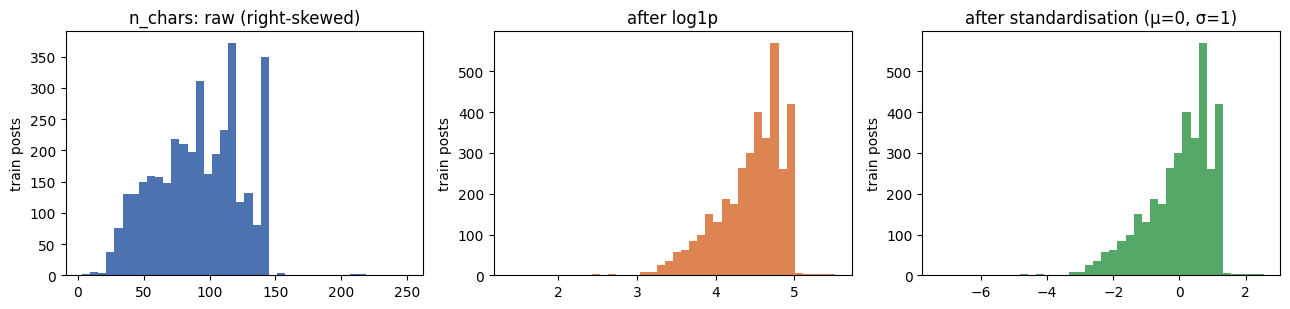

In [13]:
# Plot one feature at each stage, to show what the transformations do
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].hist(meta_raw.loc[is_train, "n_chars"], bins=40, color="#4C72B0")
ax[0].set_title("n_chars: raw (right-skewed)")
ax[1].hist(np.log1p(meta_raw.loc[is_train, "n_chars"]), bins=40, color="#DD8452")
ax[1].set_title("after log1p")
ax[2].hist(meta.loc[is_train, "n_chars"], bins=40, color="#55A868")
ax[2].set_title("after standardisation (μ=0, σ=1)")
for a in ax: a.set_ylabel("train posts")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "figures", "scaling_n_chars.png"), dpi=150)
plt.show()

## Step 8: Save everything
One file per feature group per split. Row *i* of every file is the post in line *i* of `<split>_ids.txt`.
```
preprocessed/
  posts_preprocessed.csv        all posts: id, split, raw + clean text, both labels, label, mismatch_type, flags
  preprocessing_report.json     every count logged above
  features/<split>_ids.txt      split ∈ train, val, test, hard
  features/<split>_meta.npy     standardised meta-features (column names in meta_columns.json)
  features/<split>_colorhist.npy
  features/<split>_tfidf.npz
  features/<split>_clip_text.npy, <split>_clip_image.npy
  artifacts/tfidf.joblib, scaler.joblib   fitted on train; reuse for any new data
```

In [14]:
# Write one file per feature group per split, in the same row order as <split>_ids.txt
FEAT = os.path.join(OUT_DIR, "features")
for s in SPLITS:
    m = (posts["split"] == s).values
    np.savetxt(os.path.join(FEAT, f"{s}_ids.txt"), posts.loc[m, "id"].values, fmt="%s")
    np.save(os.path.join(FEAT, f"{s}_meta.npy"), meta.loc[m].to_numpy(np.float32))
    np.save(os.path.join(FEAT, f"{s}_colorhist.npy"), colour_hist[m])
    sparse.save_npz(os.path.join(FEAT, f"{s}_tfidf.npz"), X_tfidf[m])
    if clip_text is not None:
        np.save(os.path.join(FEAT, f"{s}_clip_text.npy"), clip_text[m])
        np.save(os.path.join(FEAT, f"{s}_clip_image.npy"), clip_image[m])

with open(os.path.join(FEAT, "meta_columns.json"), "w") as f:
    json.dump(META_COLS, f, indent=1)
joblib.dump(tfidf, os.path.join(OUT_DIR, "artifacts", "tfidf.joblib"))
joblib.dump({"scaler": scaler, "scale_cols": SCALE_COLS, "log_cols": LOG_COLS, "binary_cols": BINARY_COLS},
            os.path.join(OUT_DIR, "artifacts", "scaler.joblib"))

keep = ["id", "split", "text_raw", "text_clean", "text_label", "image_label", "label", "mismatch_type",
        "text_empty", "image_path", "width", "height"]
posts[keep].to_csv(os.path.join(OUT_DIR, "posts_preprocessed.csv"), index=False)

REPORT.update({"clip_model": CLIP_MODEL if RUN_CLIP else None, "tfidf_vocab": len(tfidf.vocabulary_),
               "meta_columns": META_COLS, "seed": SEED})
with open(os.path.join(OUT_DIR, "preprocessing_report.json"), "w") as f:
    json.dump(REPORT, f, indent=1, default=int)

for root, _, files in os.walk(OUT_DIR):
    for fn in sorted(files):
        p = os.path.join(root, fn)
        print(f"{os.path.relpath(p, OUT_DIR):38s} {os.path.getsize(p) / 1024:9.1f} KB")

posts_preprocessed.csv                    1421.2 KB
preprocessing_report.json                    1.6 KB
figures/scaling_n_chars.png                 40.7 KB
artifacts/scaler.joblib                      1.9 KB
artifacts/tfidf.joblib                     182.2 KB
features/hard_clip_image.npy               710.1 KB
features/hard_clip_text.npy                710.1 KB
features/hard_colorhist.npy                 33.4 KB
features/hard_ids.txt                        1.7 KB
features/hard_meta.npy                      33.4 KB
features/hard_tfidf.npz                     34.7 KB
features/meta_columns.json                   0.3 KB
features/test_clip_image.npy               894.1 KB
features/test_clip_text.npy                894.1 KB
features/test_colorhist.npy                 42.0 KB
features/test_ids.txt                        2.1 KB
features/test_meta.npy                      42.0 KB
features/test_tfidf.npz                     36.7 KB
features/train_clip_image.npy             7182.1 KB
features/tra

## Loading the outputs in the modelling notebook
```python
import numpy as np, pandas as pd, json
from scipy import sparse
D = "/kaggle/input/<your-preprocessed-dataset>/preprocessed/features"   # or /kaggle/working/preprocessed/features
posts = pd.read_csv(D + "/../posts_preprocessed.csv", dtype={"id": str}).set_index("id")
def load(split):
    ids = np.loadtxt(f"{D}/{split}_ids.txt", dtype=str)
    y   = posts.loc[ids, "label"].values            # NaN for the 'hard' split: use text_label / image_label there
    return {"ids": ids, "y": y, "group": posts.loc[ids, "mismatch_type"].values,
            "clip_text": np.load(f"{D}/{split}_clip_text.npy"), "clip_image": np.load(f"{D}/{split}_clip_image.npy"),
            "meta": np.load(f"{D}/{split}_meta.npy"), "hist": np.load(f"{D}/{split}_colorhist.npy"),
            "tfidf": sparse.load_npz(f"{D}/{split}_tfidf.npz")}
train, val, test, hard = (load(s) for s in ["train", "val", "test", "hard"])
X_early = np.hstack([train["clip_text"], train["clip_image"]])         # early-fusion input
```
To reuse these outputs in other notebooks without re-running CLIP: *Save Version → Output → New Dataset*.